PCA con scikit-learn

In [ ]:
import numpy as np; import matplotlib.pyplot as plt
X = np.array([ [-1, -1], [0, 2], [2, 0], [3, 3] ])
N = len(X)

print(X) #matriz de datos
K = 1 #cantidad de dimensiones al que queremos reducir
_, _, Vt = np.linalg.svd(X - X.mean(0)) 
W = Vt[:K, :].T #matriz de proyeccion
Z = X @ W
hX = Z @ W.T #deconstruccion
print(hX)




[[-1 -1]
 [ 0  2]
 [ 2  0]
 [ 3  3]]
[[-1. -1.]
 [ 1.  1.]
 [ 1.  1.]
 [ 3.  3.]]


1.0


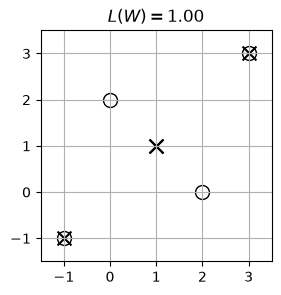

In [ ]:
L = np.square(X - hX).sum(axis=1).mean() #error de reconstruccion
print(L)

fig, ax = plt.subplots(figsize=(3, 3))
ax.set_aspect("equal")
plt.axis([-1.5, 3.5, -1.5, 3.5]); 
plt.grid(True); ax.set_title(f'$L(W)={L:.2f}$')
plt.scatter(*X.T, facecolor='white', edgecolor='k', s=100)
plt.scatter(*hX.T, facecolor='black', s=100, marker='x')

**PCA using scikit-learn**

In [3]:
import numpy as np; import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
X = np.array([ [-1, -1], [0, 2], [2, 0], [3, 3] ])
N = len(X)

K = 1 #cuantos componentes quiero 
pca = PCA(n_components=K).fit(X - X.mean(0)) #fit es para entrenar, se le pasan las muestras 
print(pca.components_) #la matrizque ha encontrado
print(pca.mean_) #media de los datos de la matriz q le pasamos, ya lo hemos pasado centrado aunque pCA tambien lo puede hacer solo
Z = pca.transform(X) # Projects the data X into the lower-dimensional principal component space (dimensionality reduction).
hX = pca.inverse_transform(Z) # Projects the data X into the lower-dimensional principal component space (dimensionality reduction).



[[0.70710678 0.70710678]]
[0. 0.]


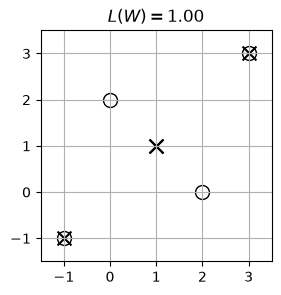

In [4]:
L = np.square(X - hX).sum(axis=1).mean()
fig, ax = plt.subplots(figsize=(3, 3))
ax.set_aspect("equal")
plt.axis([-1.5, 3.5, -1.5, 3.5])
plt.grid(True)
ax.set_title(f'$L(W)={L:.2f}$')
plt.scatter(*X.T, facecolor='white', edgecolor='k', s=100)
plt.scatter(*hX.T, facecolor='black', s=100, marker='x')

**MNIST**

In [6]:
import numpy as np; import datasets
ds = datasets.load_dataset("ylecun/mnist").with_format("numpy"); ds


DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 60000
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 10000
    })
})

In [ ]:

train0 = ds['train'][0] # Retrieves the first sample (index 0) from the training split of the MNIST dataset loaded from Hugging Face (ylecun/mnist), configured in a NumPy format.
print(train0)
print(train0['image'].shape) # Prints the dimensions of the handwritten digit image pixels, which is (28, 28) for a 28x28 pixel image.
print(train0['image'].dtype)
print(train0['label']) # one of the column names for that database is label


{'image': array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],


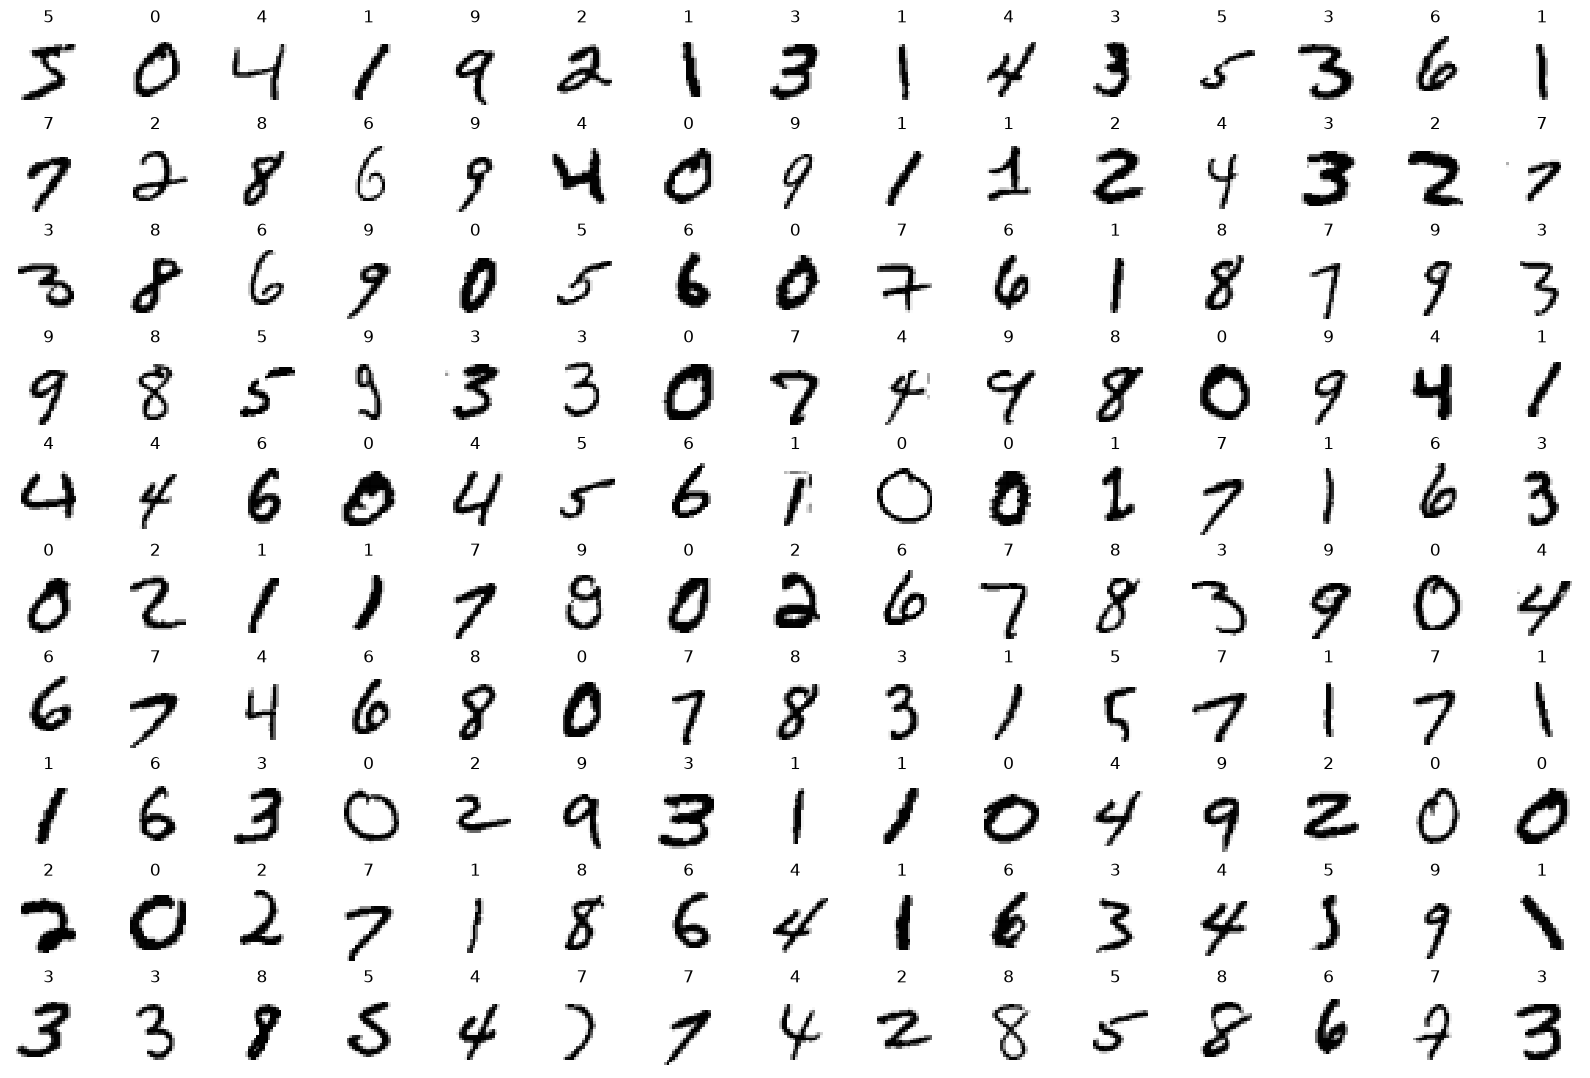

In [20]:
import matplotlib.pyplot as plt
nrows = 10
ncols = 15
N = nrows * ncols #creates a 10x15 grid
_, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 16*nrows/ncols), constrained_layout=True)
for ax, x, y in zip(axs.flat, ds['train'][:N]['image'], ds['train'][:N]['label']):
    ax.set_axis_off()
    ax.imshow(x, cmap=plt.cm.gray_r, interpolation="none")
    ax.set_title(y)


In [21]:

import numpy as np; import datasets
ds = datasets.load_dataset("ylecun/mnist").with_format("numpy")


X_train = ds['train'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
'''
Extracts all training images from the dataset (ds['train'][:]).

.astype(np.float32) converts the pixel data type from integers (uint8) to 32-bit floats, which is standard for machine learning calculations.

.reshape(-1, 28*28) flattens each 2D image (originally 28 x 28 pixels) into a 1D vector of length 784 (28 x 28). 
The -1 tells NumPy to automatically calculate the total number of training samples

./ 255. normalizes the pixel values from a range of 0 to 255 down to a decimal range of 0.0 to 1.0, helping machine learning models train faster and more stably.
'''
y_train = ds['train'][:]['label'].astype(np.uint8) #Extracts all training labels (the actual digits) and ensures they are stored as unsigned 8-bit integers (uint8).
X_test = ds['test'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)

In [14]:
ds['test'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(10000, 784), dtype=float32)

estudio de error de construccion probando diferentes dimensioens de k

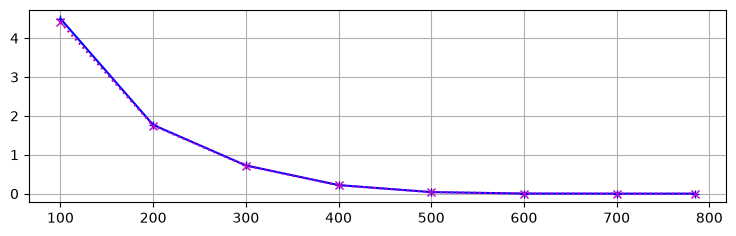

In [ ]:
import matplotlib.pyplot as plt; from sklearn.decomposition import PCA
# Calculates the maximum possible number of components. Since X_train has 60,000 rows (samples) and 784 columns (features/pixels), max_K will be 784.
max_K = np.min(X_train.shape) 

# Trains a PCA model on the training images using the maximum number of components, finding all principal axes for the dataset.
pca = PCA(n_components=max_K).fit(X_train) #transforma 

# Projects both the training and test datasets into the full principal component space.
Z_train = pca.transform(X_train)
Z_test = pca.transform(X_test)

# Defines a list of different feature counts ($K$ values) to test. This lets us see how image quality and reconstruction error change as we keep more or fewer components.
Ks = np.array([100, 200, 300, 400, 500, 600, 700, max_K])

# Creates empty arrays to store the calculated reconstruction errors for each $K$ value on both the training and test sets.
L_train = np.empty_like(Ks, dtype=float)
L_test = np.empty_like(Ks, dtype=float)

for i, K in enumerate(Ks): #prueba todas las k's pero no recalcula pca. calcula el pca de la K mas grande y luego pone a zeros para hacer los k mas pequeños para evitar calcular todo de nuevo
    Z_train_K = Z_train.copy()
    Z_train_K[:, K:] = 0.0
    hX_train = pca.inverse_transform(Z_train_K)
    L_train[i] = np.square(X_train - hX_train).sum(axis=1).mean()
    
    Z_test_K = Z_test.copy()
    Z_test_K[:, K:] = 0.0
    hX_test = pca.inverse_transform(Z_test_K)
    L_test[i] = np.square(X_test - hX_test).sum(axis=1).mean()

plt.figure(figsize=(9, 2.5)); plt.grid(True); plt.plot(Ks, L_train, '+-b', Ks, L_test, 'x:m')


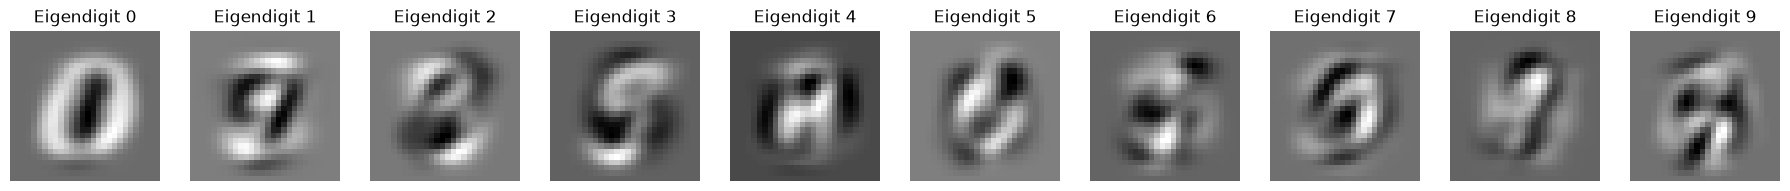

In [27]:
# Trains a PCA model using 400 components on the training dataset.
K = 100
pca = PCA(n_components=K).fit(X_train)

# Sets up a grid with 1 row and 10 columns so we can display a sequence of 10 images side-by-side.
nrows, ncols = 1, 10

# Creates the figure and the row of 10 subplot axes, with automatic layout adjustment.
fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(18, 18*nrows/ncols), constrained_layout=True)

for i in range(min(K, nrows * ncols)):
 ax = axs.flat[i]
 ax.set_axis_off()
 ax.set_title(f"Eigendigit {i}")

 ''' 
 Extracts the i-th principal component vector (pca.components_[i, :]) of length 784.
 .reshape((28, 28)) reshapes that flat vector back into a 28 x 28 image shape so it can be drawn as a picture
 .imshow(...) displays it in grayscale. 
 These pictures show the underlying "building block" patterns (loops, strokes, and curves) that the model uses to construct digits.'''
 ax.imshow(pca.components_[i, :].reshape((28, 28)), cmap=plt.cm.gray, interpolation="none")

#son los pesos de cada cosa. pesos que sean 0 son irrelevantes 


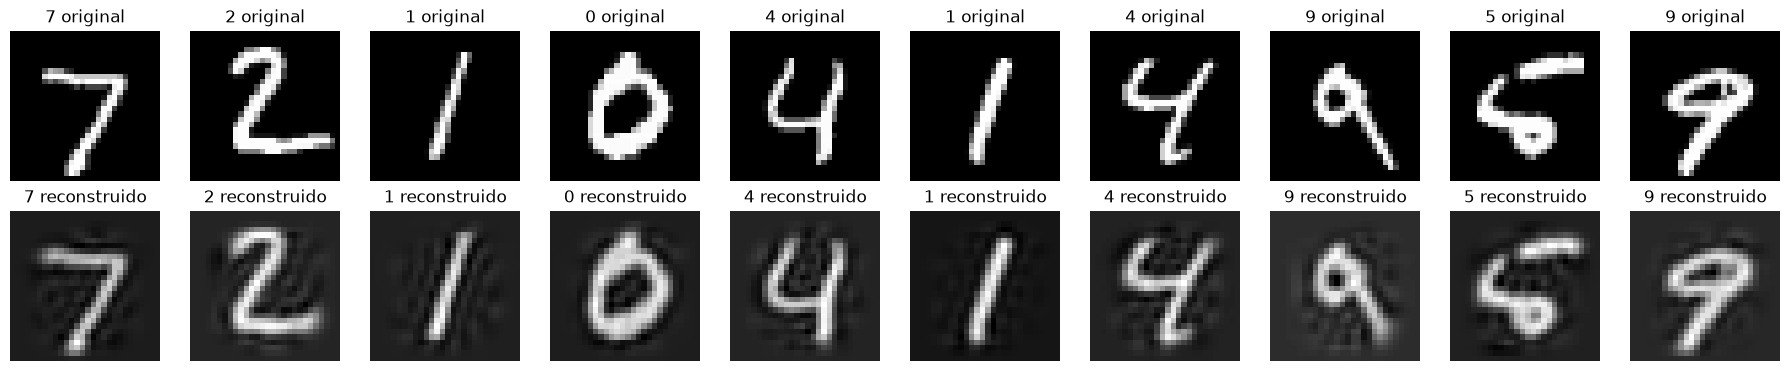

In [28]:


ncols = 10 # Sets up 10 columns (meaning we will display 10 digits).
Z_test = pca.transform(X_test[:ncols]) # Takes the first 10 test images and projects them into the PCA space (compressing them).
hX_test = pca.inverse_transform(Z_test) #Reconstructs those compressed versions back into 784-pixel image vectors.

# Creates a grid of subplots with 2 rows and 10 columns (total of 20 boxes). 
# The top row will display the original images, and the bottom row will display the compressed/reconstructed ones.
fig, axs = plt.subplots(nrows=2, ncols=10, figsize=(18, 18*2/ncols), constrained_layout=True)

for i in range(ncols):
    # Selects the subplot in the top row (i), hides the axis lines and numbers, and sets the title to the correct digit label followed by "original" (e.g., "7 original").
    ax = axs.flat[i]
    ax.set_axis_off()
    ax.set_title(f"{y_test[i]} original")

    # Reshapes the flat 784-length vector of the original test image back into a $28 \times 28$ pixel grid and displays it in grayscale.
    ax.imshow(X_test[i, :].reshape((28, 28)), cmap=plt.cm.gray, interpolation="none")
    ax = axs.flat[ncols + i]
    ax.set_axis_off()
    ax.set_title(f"{y_test[i]} reconstruido")

    # Reshapes the reconstructed image vector back into a $28 \times 28$ grid and displays it directly below the original image so you can visually see how much detail was preserved after PCA compression!
    ax.imshow(hX_test[i, :].reshape((28, 28)), cmap=plt.cm.gray, interpolation="none")


**Regresion logistica**

Here is a line-by-line explanation of this code snippet, which trains a Logistic Regression classifier on the PCA-compressed MNIST data and evaluates how its classification accuracy changes as you use more principal components ($K$):

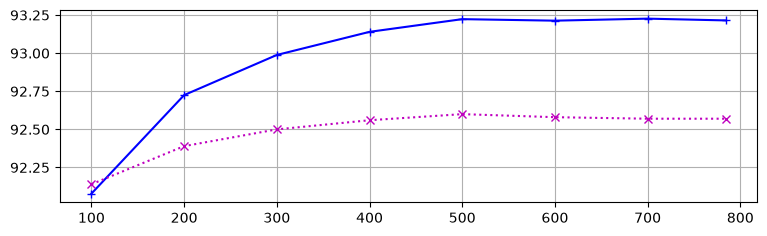

In [29]:

from sklearn.linear_model import LogisticRegression

# Finds the maximum number of components (784 features for the flattened MNIST images).
max_K = np.min(X_train.shape)

# Trains a full PCA model on the training data to find all principal components.
pca = PCA(n_components=max_K).fit(X_train)

# Transforms both the training and test datasets into the full PCA space.
Z_train = pca.transform(X_train)
Z_test = pca.transform(X_test)

Ks = np.array([100, 200, 300, 400, 500, 600, 700, max_K])

# Creates empty arrays to store the accuracy scores for each $K$ value on both the training and test sets.
acc_train = np.empty_like(Ks, dtype=float)
acc_test = np.empty_like(Ks, dtype=float)


for i, K in enumerate(Ks):
    ''' 
    Trains a logistic regression model using only the first K components (Z_train[:, :K]) and the true digit labels (y_train).
    C=0.1 is a regularization hyperparameter (controls model complexity to prevent overfitting).
    max_iter=200 sets the maximum number of optimization steps for the solver to find the best fit.
    '''
    clf = LogisticRegression(C=0.1, max_iter=200).fit(Z_train[:, :K], y_train) #metaparametros

    # Calculates and saves the model's accuracy (percentage of correct predictions) on the training set using those first K features.
    acc_train[i] = clf.score(Z_train[:, :K], y_train)
    # Calculates and saves the model's accuracy on the unseen test set using those first K features
    acc_test[i] = clf.score(Z_test[:, :K], y_test)


plt.figure(figsize=(9, 2.5)); plt.grid(True)
plt.plot(Ks, 100. * acc_train, '+-b', Ks, 100. * acc_test, 'x:m')

****Ejercicios****

aplica PCA a Fashion-MNIST y CIFAR-10 siguiendo el ejemplo dado para MNIST

Fashion-MNIST

In [19]:
import numpy as np; import datasets
ds = datasets.load_dataset("zalando-datasets/fashion_mnist").with_format("numpy"); ds

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 60000
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 10000
    })
})

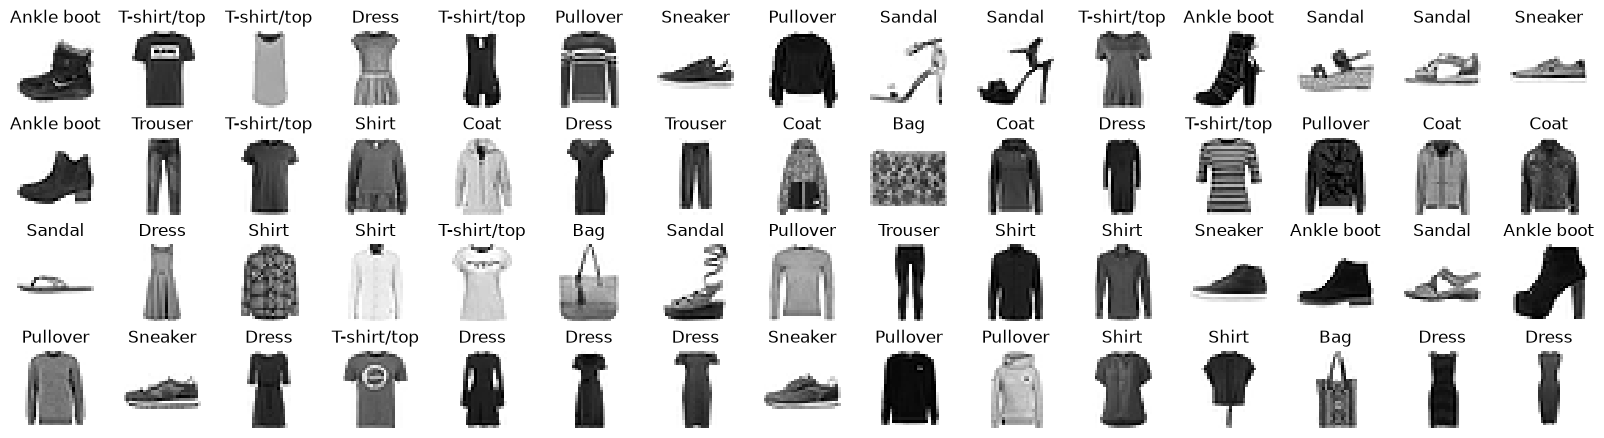

In [ ]:
import matplotlib.pyplot as plt

nrows = 4
ncols = 15
N = nrows * ncols
labels = ("T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot")
_, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 16*nrows/ncols), constrained_layout=True)

for ax, x, y in zip(axs.flat, ds['train'][:N]['image'], ds['train'][:N]['label']):
    ax.set_axis_off(); ax.imshow(x, cmap=plt.cm.gray_r, interpolation="none"); ax.set_title(labels[y])

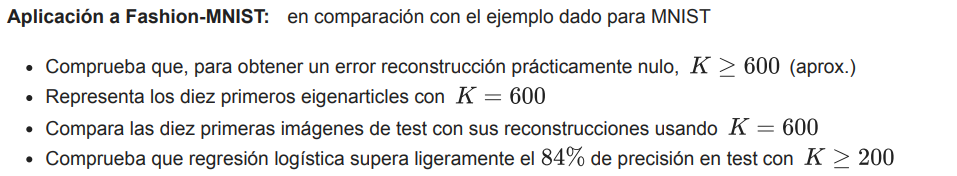

In [30]:
import numpy as np; import datasets
ds = datasets.load_dataset("zalando-datasets/fashion_mnist").with_format("numpy")
X_train = ds['train'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_train = ds['train'][:]['label'].astype(np.uint8)
X_test = ds['test'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)


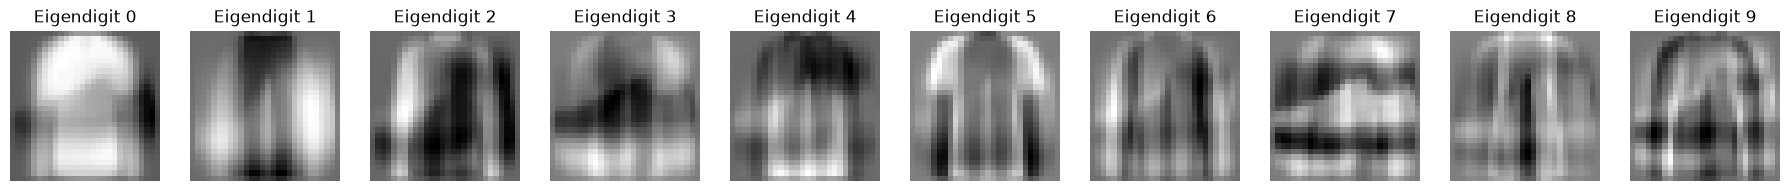

In [ ]:
K = 600
pca = PCA(n_components=K).fit(X_train)
nrows, ncols = 1, 10

fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(18, 18*nrows/ncols), constrained_layout=True)

for i in range(min(K, nrows * ncols)):
    ax = axs.flat[i]; ax.set_axis_off(); ax.set_title(f"Eigendigit {i}")
    ax.imshow(pca.components_[i, :].reshape((28, 28)), cmap=plt.cm.gray, interpolation="none")


error de reconstruccion co ndiferentes k

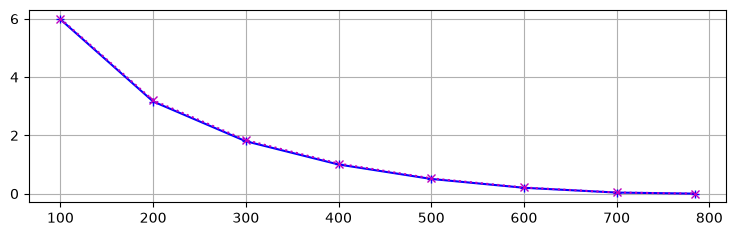

In [32]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

max_K = np.min(X_train.shape)
pca = PCA(n_components=max_K).fit(X_train)
Z_train = pca.transform(X_train)
Z_test = pca.transform(X_test)
Ks = np.array([100, 200, 300, 400, 500, 600, 700, max_K])
L_train = np.empty_like(Ks, dtype=float)
L_test = np.empty_like(Ks, dtype=float)

for i, K in enumerate(Ks):
    Z_train_K = Z_train.copy()
    Z_train_K[:, K:] = 0.0
    hX_train = pca.inverse_transform(Z_train_K)
    L_train[i] = np.square(X_train - hX_train).sum(axis=1).mean()
    Z_test_K = Z_test.copy()
    Z_test_K[:, K:] = 0.0
    hX_test = pca.inverse_transform(Z_test_K)
    L_test[i] = np.square(X_test - hX_test).sum(axis=1).mean()

plt.figure(figsize=(9, 2.5)); plt.grid(True)
plt.plot(Ks, L_train, '+-b', Ks, L_test, 'x:m')

compara los 10 primeros imagenes con sus reconstrucciones

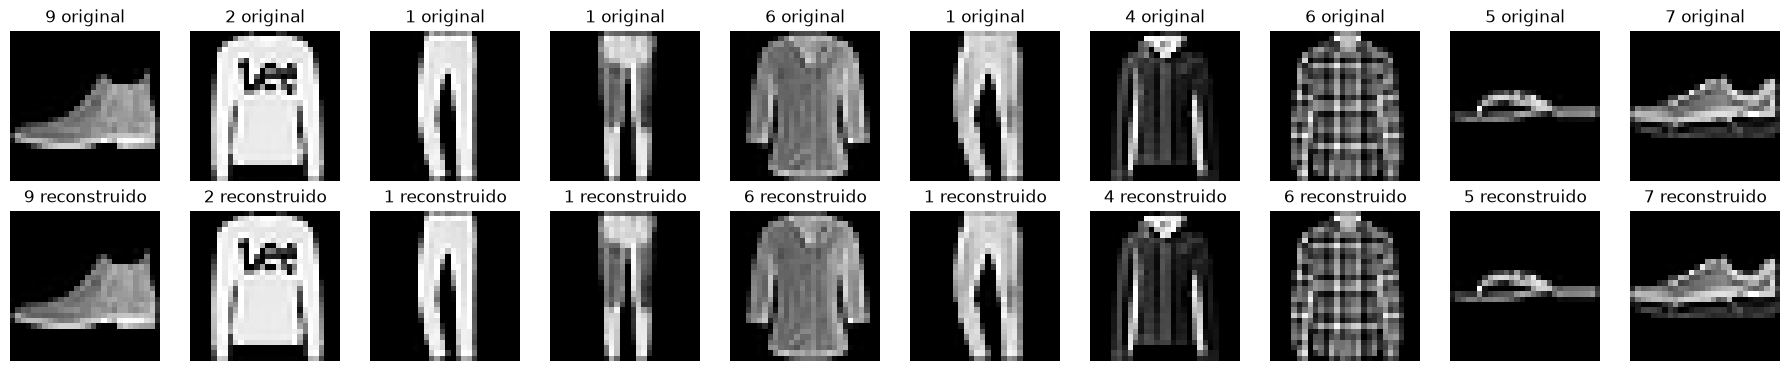

In [33]:
ncols = 10
Z_test = pca.transform(X_test[:ncols])
hX_test = pca.inverse_transform(Z_test)

fig, axs = plt.subplots(nrows=2, ncols=10, figsize=(18, 18*2/ncols), constrained_layout=True)

for i in range(ncols):
    ax = axs.flat[i]
    ax.set_axis_off()
    ax.set_title(f"{y_test[i]} original")
    ax.imshow(X_test[i, :].reshape((28, 28)), cmap=plt.cm.gray, interpolation="none")
    ax = axs.flat[ncols + i]
    ax.set_axis_off()
    ax.set_title(f"{y_test[i]} reconstruido")
    ax.imshow(hX_test[i, :].reshape((28, 28)), cmap=plt.cm.gray, interpolation="none")


regresion logistica

c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/pre

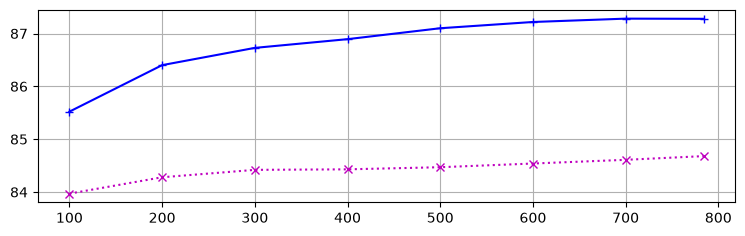

In [34]:
from sklearn.linear_model import LogisticRegression

max_K = np.min(X_train.shape)
pca = PCA(n_components=max_K).fit(X_train)
Z_train = pca.transform(X_train)
Z_test = pca.transform(X_test)
Ks = np.array([100, 200, 300, 400, 500, 600, 700, max_K])
acc_train = np.empty_like(Ks, dtype=float)
acc_test = np.empty_like(Ks, dtype=float)

for i, K in enumerate(Ks):
    clf = LogisticRegression(C=0.1, max_iter=200).fit(Z_train[:, :K], y_train)
    acc_train[i] = clf.score(Z_train[:, :K], y_train)
    acc_test[i] = clf.score(Z_test[:, :K], y_test)

plt.figure(figsize=(9, 2.5)); plt.grid(True)
plt.plot(Ks, 100. * acc_train, '+-b', Ks, 100. * acc_test, 'x:m')


****CIFAR - 10****

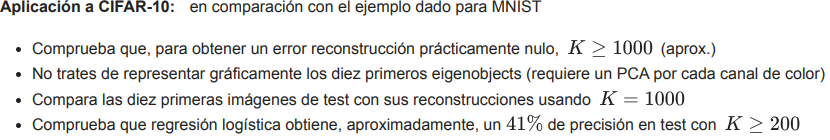

In [35]:
import numpy as np
import datasets
ds = datasets.load_dataset("uoft-cs/cifar10").with_format("numpy")
ds


DatasetDict({
    train: Dataset({
        features: ['img', 'label'],
        num_rows: 50000
    })
    test: Dataset({
        features: ['img', 'label'],
        num_rows: 10000
    })
})

In [36]:

train0 = ds['train'][0]
train0['img'].shape, train0['img'].dtype, train0['label']


((32, 32, 3), dtype('uint8'), np.int64(0))

In [ ]:
import numpy as np
import datasets

X_train = ds['train'][:]['img'].astype(np.float32).reshape(-1, 32*32*3) / 255.
y_train = ds['train'][:]['label'].astype(np.uint8)
X_test = ds['test'][:]['img'].astype(np.float32).reshape(-1, 32*32*3) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)

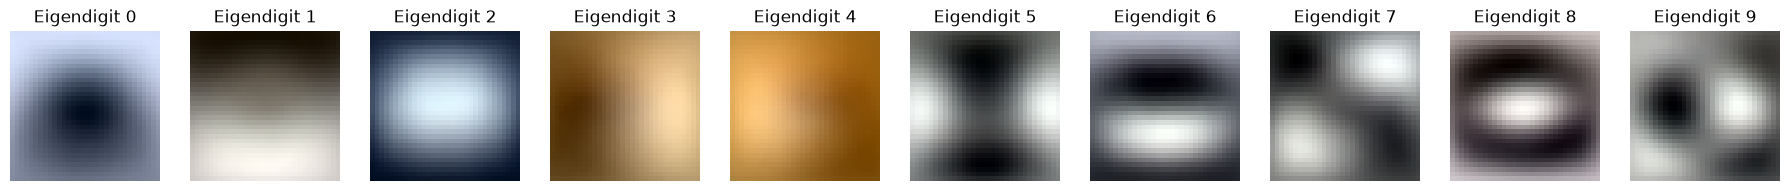

In [40]:
K = 1000
pca = PCA(n_components=K).fit(X_train)
nrows, ncols = 1, 10

fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(18, 18*nrows/ncols), constrained_layout=True)

for i in range(min(K, nrows * ncols)):
    ax = axs.flat[i]
    ax.set_axis_off()
    ax.set_title(f"Eigendigit {i}")

    # 1. Reshape to RGB image shape (32, 32, 3)
    img = pca.components_[i, :].reshape((32, 32, 3))
    
    # 2. Normalize values between 0 and 1 to prevent clipping warnings
    img_normalized = (img - img.min()) / (img.max() - img.min())
    
    # 3. Display without a grayscale colormap (since it's RGB)
    ax.imshow(img_normalized, interpolation="none")

    # ax.imshow(pca.components_[i, :].reshape((32, 32, 3)), cmap=plt.cm.gray, interpolation="none")


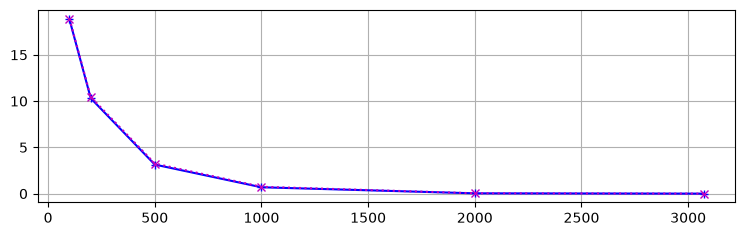

In [42]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

max_K = np.min(X_train.shape)
pca = PCA(n_components=max_K).fit(X_train)
Z_train = pca.transform(X_train)
Z_test = pca.transform(X_test)
Ks = np.array([100, 200, 500, 1000, 2000, max_K])
L_train = np.empty_like(Ks, dtype=float)
L_test = np.empty_like(Ks, dtype=float)

for i, K in enumerate(Ks):
    Z_train_K = Z_train.copy()
    Z_train_K[:, K:] = 0.0
    hX_train = pca.inverse_transform(Z_train_K)
    L_train[i] = np.square(X_train - hX_train).sum(axis=1).mean()
    Z_test_K = Z_test.copy()
    Z_test_K[:, K:] = 0.0
    hX_test = pca.inverse_transform(Z_test_K)
    L_test[i] = np.square(X_test - hX_test).sum(axis=1).mean()

plt.figure(figsize=(9, 2.5)); plt.grid(True)
plt.plot(Ks, L_train, '+-b', Ks, L_test, 'x:m')

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.4703484e-07..0.96862733].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-8.940697e-08..0.82745165].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [2.3841858e-07..1.0000002].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.03529367..1.0000006].


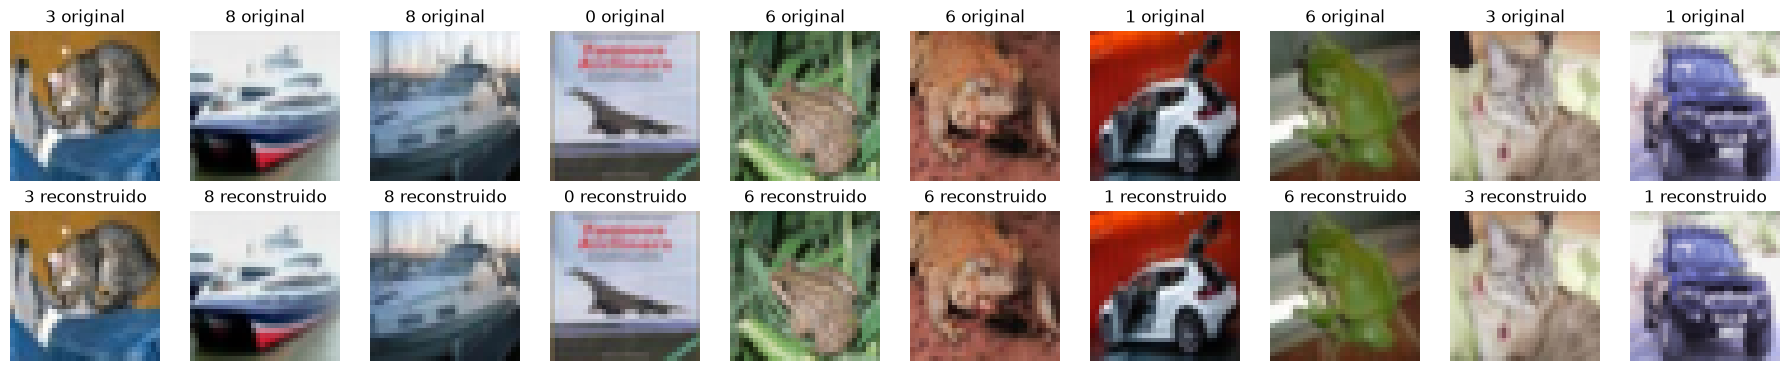

In [44]:
ncols = 10
Z_test = pca.transform(X_test[:ncols])
hX_test = pca.inverse_transform(Z_test)

fig, axs = plt.subplots(nrows=2, ncols=10, figsize=(18, 18*2/ncols), constrained_layout=True)

for i in range(ncols):
    ax = axs.flat[i]
    ax.set_axis_off()
    ax.set_title(f"{y_test[i]} original")
    ax.imshow(X_test[i, :].reshape((32, 32, 3)), cmap=plt.cm.gray, interpolation="none")
    ax = axs.flat[ncols + i]
    ax.set_axis_off()
    ax.set_title(f"{y_test[i]} reconstruido")
    ax.imshow(hX_test[i, :].reshape((32, 32, 3)), cmap=plt.cm.gray, interpolation="none")


c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/pre

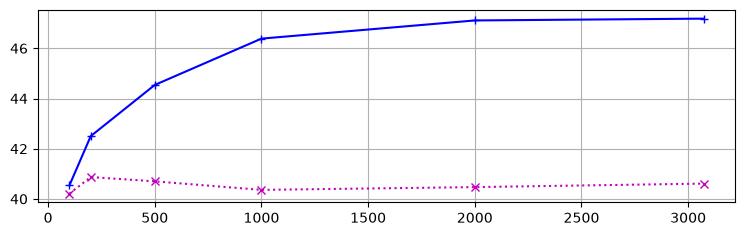

In [45]:
from sklearn.linear_model import LogisticRegression

max_K = np.min(X_train.shape)
pca = PCA(n_components=max_K).fit(X_train)
Z_train = pca.transform(X_train)
Z_test = pca.transform(X_test)
Ks = np.array([100, 200, 500, 1000, 2000, max_K])
acc_train = np.empty_like(Ks, dtype=float)
acc_test = np.empty_like(Ks, dtype=float)

for i, K in enumerate(Ks):
    clf = LogisticRegression(C=0.1, max_iter=200).fit(Z_train[:, :K], y_train)
    acc_train[i] = clf.score(Z_train[:, :K], y_train)
    acc_test[i] = clf.score(Z_test[:, :K], y_test)

plt.figure(figsize=(9, 2.5)); plt.grid(True)
plt.plot(Ks, 100. * acc_train, '+-b', Ks, 100. * acc_test, 'x:m')


In [46]:
for i, K in enumerate(Ks): 
    print(f'{K} {acc_test[i]:.1%}', end=' ')


100 40.2% 200 40.9% 500 40.7% 1000 40.4% 2000 40.5% 3072 40.6% 